# ConcretoAI — Estimativa da resistência à compressão do concreto

**Disciplina:** Machine Learning — Pós-Graduação em IA Generativa e Aplicações com LLMs, PUC Minas (Prof. Maurício Rodrigues da Silva)
**Integrantes:** Mateus, Yara, Paulo, Carlos e Eduardo
**Dataset:** Concrete Compressive Strength — base pública do UCI Machine Learning Repository (I-Cheng Yeh). Página oficial: https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength · DOI: https://doi.org/10.24432/C5PK67 · Licença: [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) (informada na página oficial)
**Objetivo:** estimar a resistência à compressão do concreto (MPa) a partir da composição da mistura (kg/m³) e da idade (dias).
**Técnica:** regressão supervisionada (Ridge e RandomForestRegressor, comparados por validação cruzada).

**Crédito e referência:** dataset criado e doado por I-Cheng Yeh (Chung-Hua University, Taiwan), uso conforme CC BY 4.0 com atribuição. O readme original da fonte pede a retenção do aviso de autoria e a citação de: I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," *Cement and Concrete Research*, Vol. 28, No. 12, pp. 1797–1808 (1998).

## 1. Importação de bibliotecas e configuração

Todas as importações ficam nesta célula. A semente `np.random.seed(42)` garante reprodutibilidade. Os caminhos são resolvidos a partir da raiz do trabalho, de modo que o notebook funciona tanto se executado pela raiz (`tarefa-05-final`) quanto pela pasta `notebooks`.

In [1]:
from importlib import metadata as package_metadata
import json
import platform
import sys
import joblib
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import ScalarFormatter
from sklearn.model_selection import GroupShuffleSplit

np.random.seed(42)
SEED = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

# Raiz do trabalho: a pasta que contém data/raw (cwd ou o pai dela, se estiver em notebooks/)
CWD = Path.cwd().resolve()
RAIZ = next((p for p in (CWD, CWD.parent) if (p / "data" / "raw").is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError("Execute o notebook a partir de tarefa-05-final ou de tarefa-05-final/notebooks.")

ARQUIVO_DADOS = RAIZ / "data" / "raw" / "Concrete_Data.xls"
print("Raiz do trabalho:", RAIZ.name)
DIR_FIGURAS = RAIZ / "reports" / "figures"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_PROCESSADOS = RAIZ / "data" / "processed"
DIR_PROCESSADOS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.35})
COR_PRINCIPAL = "#2a6f97"   # cor única para gráficos de uma só série
COR_DESTAQUE = "#c8553d"    # linhas de referência (média/mediana)

print("Arquivo de dados:", ARQUIVO_DADOS.relative_to(RAIZ), "| existe:", ARQUIVO_DADOS.exists())
print("pandas", pd.__version__, "| numpy", np.__version__)

Raiz do trabalho: tarefa-05-final
Arquivo de dados: data\raw\Concrete_Data.xls | existe: True
pandas 3.0.6 | numpy 2.5.3


## 2. Carregamento dos dados

O arquivo original `Concrete_Data.xls` (planilha `Sheet1`) é lido sem nenhuma alteração. Antes de renomear, **conferimos os nomes originais das colunas**: eles trazem a unidade embutida, espaços duplicados e espaço no final. O renomeio usa um mapeamento explícito e falha se algum nome original for diferente do esperado.

In [2]:
df_bruto = pd.read_excel(ARQUIVO_DADOS, sheet_name="Sheet1")

print("Nomes originais das colunas (repr mostra espaços extras):")
for i, c in enumerate(df_bruto.columns):
    print(f"  {i}: {c!r}")

Nomes originais das colunas (repr mostra espaços extras):
  0: 'Cement (component 1)(kg in a m^3 mixture)'
  1: 'Blast Furnace Slag (component 2)(kg in a m^3 mixture)'
  2: 'Fly Ash (component 3)(kg in a m^3 mixture)'
  3: 'Water  (component 4)(kg in a m^3 mixture)'
  4: 'Superplasticizer (component 5)(kg in a m^3 mixture)'
  5: 'Coarse Aggregate  (component 6)(kg in a m^3 mixture)'
  6: 'Fine Aggregate (component 7)(kg in a m^3 mixture)'
  7: 'Age (day)'
  8: 'Concrete compressive strength(MPa, megapascals) '


In [3]:
MAPA_COLUNAS = {
    "Cement (component 1)(kg in a m^3 mixture)": "cimento",
    "Blast Furnace Slag (component 2)(kg in a m^3 mixture)": "escoria",
    "Fly Ash (component 3)(kg in a m^3 mixture)": "cinza_volante",
    "Water  (component 4)(kg in a m^3 mixture)": "agua",
    "Superplasticizer (component 5)(kg in a m^3 mixture)": "superplastificante",
    "Coarse Aggregate  (component 6)(kg in a m^3 mixture)": "agregado_graudo",
    "Fine Aggregate (component 7)(kg in a m^3 mixture)": "agregado_miudo",
    "Age (day)": "idade_dias",
    "Concrete compressive strength(MPa, megapascals) ": "resistencia_mpa",
}
assert list(df_bruto.columns) == list(MAPA_COLUNAS), "Nomes originais diferem do esperado; revisar o mapeamento."

df = df_bruto.rename(columns=MAPA_COLUNAS)
ALVO = "resistencia_mpa"
FEATURES = [c for c in df.columns if c != ALVO]

UNIDADES = {c: "kg/m³" for c in FEATURES}
UNIDADES.update({"idade_dias": "dias", ALVO: "MPa"})
print("Features:", FEATURES)
print("Alvo:", ALVO)
pd.DataFrame({"unidade": UNIDADES})

Features: ['cimento', 'escoria', 'cinza_volante', 'agua', 'superplastificante', 'agregado_graudo', 'agregado_miudo', 'idade_dias']
Alvo: resistencia_mpa


,unidade
cimento,kg/m³
escoria,kg/m³
cinza_volante,kg/m³
agua,kg/m³
superplastificante,kg/m³
agregado_graudo,kg/m³
agregado_miudo,kg/m³
idade_dias,dias
resistencia_mpa,MPa


## 3. Visão geral: dimensões, amostra e tipos

`shape` informa registros e colunas; `head()` mostra as primeiras linhas; `info()` mostra tipos e contagem de valores não nulos.

In [4]:
print("shape (registros, colunas):", df.shape)
df.head()

shape (registros, colunas): (1030, 9)


,cimento,escoria,cinza_volante,agua,superplastificante,agregado_graudo,agregado_miudo,idade_dias,resistencia_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cimento             1030 non-null   float64
 1   escoria             1030 non-null   float64
 2   cinza_volante       1030 non-null   float64
 3   agua                1030 non-null   float64
 4   superplastificante  1030 non-null   float64
 5   agregado_graudo     1030 non-null   float64
 6   agregado_miudo      1030 non-null   float64
 7   idade_dias          1030 non-null   int64  
 8   resistencia_mpa     1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


## 4. Qualidade dos dados: nulos, zeros, duplicatas e conflitos

- **Nulos:** valores realmente ausentes (`NaN`).
- **Zeros:** são apenas **contados para informação**. Em concreto, zero em escória, cinza volante ou superplastificante significa que o componente **não foi usado na mistura** — é um valor legítimo, não dado ausente. Por isso zeros **não** são tratados como nulos.
- **Duplicatas:** linhas totalmente idênticas (todas as colunas, incluindo o alvo). **Nada é excluído automaticamente** nesta etapa.
- **Conflitos:** entradas (features) idênticas com resistências diferentes.

In [6]:
nulos = df.isna().sum()
zeros = (df == 0).sum()
print("Total de valores nulos:", int(nulos.sum()))
pd.DataFrame({"nulos": nulos, "zeros (legítimos, só informativo)": zeros, "% zeros": (zeros / len(df) * 100).round(1)})

Total de valores nulos: 0


,nulos,"zeros (legítimos, só informativo)",% zeros
cimento,0,0,0.0
escoria,0,466,45.2
cinza_volante,0,566,55.0
agua,0,0,0.0
superplastificante,0,379,36.8
agregado_graudo,0,0,0.0
agregado_miudo,0,0,0.0
idade_dias,0,0,0.0
resistencia_mpa,0,0,0.0


In [7]:
mascara_dup = df.duplicated(keep=False)
n_redundantes = int(df.duplicated(keep="first").sum())
print("Linhas que pertencem a algum grupo duplicado:", int(mascara_dup.sum()))
print("Linhas redundantes (cópias além da primeira ocorrência):", n_redundantes)
print("Grupos duplicados distintos:", int(df[mascara_dup].drop_duplicates().shape[0]))
df[mascara_dup].sort_values(FEATURES + [ALVO]).head(20)

Linhas que pertencem a algum grupo duplicado: 36
Linhas redundantes (cópias além da primeira ocorrência): 25
Grupos duplicados distintos: 11


,cimento,escoria,cinza_volante,agua,superplastificante,agregado_graudo,agregado_miudo,idade_dias,resistencia_mpa
801,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
809,252.0,0.0,0.0,185.0,0.0,1111.0,784.0,28,19.691435
83,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
86,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
88,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
91,362.6,189.0,0.0,164.9,11.6,944.7,755.8,3,35.301171
106,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
109,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
111,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,55.895819
129,362.6,189.0,0.0,164.9,11.6,944.7,755.8,28,71.298713


In [8]:
# Mesmas features, resistências diferentes?
grupos = df.groupby(FEATURES)[ALVO]
resumo = grupos.agg(n_linhas="size", n_alvos_distintos="nunique", min_mpa="min", max_mpa="max")
conflitos = resumo[resumo["n_alvos_distintos"] > 1]
print("Combinações de features que se repetem:", int((resumo["n_linhas"] > 1).sum()))
print("Combinações idênticas com resistências diferentes:", len(conflitos))
conflitos if len(conflitos) else "Nenhum conflito encontrado."

Combinações de features que se repetem: 19
Combinações idênticas com resistências diferentes: 9


n_linhas  n_alvos_distintos    min_mpa    max_mpa
cimento escoria cinza_volante agua  superplastificante agregado_graudo agregado_miudo idade_dias                                                   
359.0   19.0    141.0         154.0 10.91              942.0           801.0          3                  2                  2  23.639177  25.116626
                                                                                      7                  2                  2  35.754255  38.610656
                                                                                      28                 2                  2  59.494884  62.935369
                                                                                      56                 2                  2  66.780675  68.750607
362.6   189.0   0.0           164.9 11.60              944.7           755.8          7                  4                  2  22.897498  55.895819
446.0   24.0    79.0          162.0 11.64              967.0           712.0          3                  2                  2  23.345657  25.021084
                                                                                      7                  2                  2  38.017707  39.300132
                                                                                      28                 2                  2  44.422939  51.021224
                                                                                      56                 2                  2  55.254607  56.144031

## 5. Estatísticas descritivas

`describe()` resume contagem, média, desvio, mínimo, quartis e máximo de cada coluna. Serve para checar escalas e faixas plausíveis (úteis depois na validação da interface).

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
cimento,1030.0,281.165631,104.507142,102.000000,192.375000,272.900000,350.000000,540.000000
escoria,1030.0,73.895485,86.279104,0.000000,0.000000,22.000000,142.950000,359.400000
cinza_volante,1030.0,54.187136,63.996469,0.000000,0.000000,0.000000,118.270000,200.100000
agua,1030.0,181.566359,21.355567,121.750000,164.900000,185.000000,192.000000,247.000000
superplastificante,1030.0,6.203112,5.973492,0.000000,0.000000,6.350000,10.160000,32.200000
agregado_graudo,1030.0,972.918592,77.753818,801.000000,932.000000,968.000000,1029.400000,1145.000000
agregado_miudo,1030.0,773.578883,80.175427,594.000000,730.950000,779.510000,824.000000,992.600000
idade_dias,1030.0,45.662136,63.169912,1.000000,7.000000,28.000000,56.000000,365.000000
resistencia_mpa,1030.0,35.817836,16.705679,2.331808,23.707115,34.442774,46.136287,82.599225


## 6. Resultados da inspeção

Resultados obtidos na execução acima:

- **Dimensões:** 1030 registros e 9 colunas (8 features + 1 alvo), em linha com o readme da fonte. Todas as colunas são numéricas (8 `float64` e `idade_dias` como `int64`); não há variáveis categóricas, então não será necessário *encoding*.
- **Nulos:** 0 em todas as colunas.
- **Zeros:** aparecem em `escoria` (466, 45,2 %), `cinza_volante` (566, 55,0 %) e `superplastificante` (379, 36,8 %). Significam que o componente não entrou na mistura, e **não** foram tratados como ausência. Cimento, água, agregados, idade e resistência não têm zeros.
- **Duplicatas:** 36 linhas pertencem a 11 grupos de linhas totalmente idênticas, o que dá **25 linhas redundantes** (cópias além da primeira). Nada foi removido. Trata-se de ensaios repetidos da mesma mistura/idade ou de repetição no registro; a decisão fica para a etapa de pré-processamento. Ponto de atenção: se cópias idênticas caírem em treino e teste ao mesmo tempo, o desempenho no teste pode ficar levemente otimista.
- **Conflitos:** 19 combinações de features se repetem e, em **9 delas**, a mesma entrada tem resistências diferentes (diferenças em geral pequenas, na casa de 1 a 7 MPa). A exceção é a mistura com cimento 362,6 e idade de 7 dias, que tem 4 linhas com resistências entre 22,9 e 55,9 MPa — diferença grande que merece atenção. Isso é esperado em dados de laboratório (variabilidade do ensaio) e indica um **limite de ruído** que nenhum modelo consegue eliminar. Também não foi removido nada.
- **Escalas:** os componentes variam de dezenas a mais de mil kg/m³ (`agregado_graudo` chega a 1145; `superplastificante` a 32,2) e a idade vai de 1 a 365 dias. As escalas são muito diferentes, o que justifica padronização dentro do pipeline para o Ridge.
- **Alvo:** `resistencia_mpa` varia de 2,33 a 82,60 MPa, com média de 35,82 e mediana de 34,44 MPa. Estes limites servirão de referência para definir faixas plausíveis na interface.

### Encaminhamentos
- As duplicatas exatas são tratadas na seção 8, antes da separação treino/teste.
- As quatro análises exploratórias (distribuição, alvo, correlação e domínio) vêm na seção 10.

## 7. Conferência das abas extras do arquivo

O `Concrete_Data.xls` tem três abas. Os dados usados vêm de `Sheet1`. Antes de seguir, conferimos se `Sheet2` e `Sheet3` contêm algo relevante.

In [10]:
for aba in ["Sheet2", "Sheet3"]:
    extra = pd.read_excel(ARQUIVO_DADOS, sheet_name=aba, header=None)
    print(f"{aba}: shape = {extra.shape} | células preenchidas = {int(extra.notna().sum().sum())}")

Sheet2: shape = (0, 0) | células preenchidas = 0
Sheet3: shape = (0, 0) | células preenchidas = 0


**Resultado:** `Sheet2` e `Sheet3` estão **vazias** (shape `(0, 0)` e 0 células preenchidas). Não há dados relevantes fora de `Sheet1`, então a análise segue só com `Sheet1`. Os arquivos em `data/raw` não foram alterados.

## 8. Preparação dos dados: cópia de trabalho e duplicatas exatas

Trabalhamos sobre uma **cópia** (`df_trab`); `df` e os arquivos em `data/raw` permanecem intactos.

**Decisão do projeto:** remover apenas as **duplicatas exatas**, isto é, linhas iguais nas **nove colunas** (as oito entradas e `resistencia_mpa`), mantendo a primeira ocorrência. O motivo é evitar repetir registros indistinguíveis, que pesariam mais no treino e poderiam inflar a avaliação. Isso é uma escolha do projeto: **não** afirmamos que essas linhas sejam comprovadamente cópias de um mesmo ensaio, nem que não representem medições independentes — o que se sabe é que, nos dados, elas não se distinguem.

O que **não** fazemos: não removemos entradas iguais com resistências diferentes, não calculamos média nem escolhemos uma das resistências, não declaramos erro na fonte, não tratamos zeros como ausência e não removemos *outliers*. O índice original das linhas é preservado (sem `reset_index`) para rastreabilidade.

In [11]:
df_trab = df.copy()

n_antes = len(df_trab)
df_trab = df_trab.drop_duplicates(keep="first")   # as nove colunas, incluindo resistencia_mpa
n_depois = len(df_trab)
print(f"Antes: {n_antes} | removidas: {n_antes - n_depois} | depois: {n_depois}")
assert n_antes - n_depois == int(df.duplicated().sum())

# Conferências: entradas iguais com alvos diferentes seguem preservadas; zeros intactos
conflitos_depois = df_trab.groupby(FEATURES)[ALVO].nunique()
print("Entradas idênticas com resistências diferentes (preservadas):", int((conflitos_depois > 1).sum()))
print("Nulos:", int(df_trab.isna().sum().sum()), "| zeros preservados em escoria/cinza_volante/superplastificante:",
      int((df_trab[["escoria", "cinza_volante", "superplastificante"]] == 0).sum().sum()))

Antes: 1030 | removidas: 25 | depois: 1005
Entradas idênticas com resistências diferentes (preservadas): 9
Nulos: 0 | zeros preservados em escoria/cinza_volante/superplastificante: 1384


**Resultado:** a base de trabalho passou de **1030** para **1005** linhas, com **25** removidas — exatamente o esperado pela inspeção anterior (1030 − 25). As **9** combinações de entradas idênticas com resistências diferentes continuam na base, sem média nem escolha entre os valores; também permanecem todos os zeros legítimos (1384 zeros somados em escória, cinza volante e superplastificante) e nenhum valor foi tratado como ausente. Nenhum *outlier* foi removido.

## 9. Separação treino/teste por grupos

**X e y.** `X` recebe as oito entradas; `y`, `resistencia_mpa`.

**Grupos.** Cada grupo é uma combinação **exata das oito entradas** (inclui `idade_dias`; o alvo **não** é usado). Linhas com entradas idênticas ficam sempre no mesmo grupo, e portanto no mesmo conjunto. O identificador do grupo serve só para separar e, depois, para a validação cruzada; **não entra nas features do modelo**.

**Separação.** `GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)`. Os 20% valem para os **grupos**, não exatamente para as linhas (grupos com mais de uma linha deslocam a proporção). A separação é feita **uma vez**, com semente fixa, e **não** será trocada depois de olhar resultados do alvo. O conjunto de teste fica reservado para a avaliação final do modelo escolhido.

In [12]:
X = df_trab[FEATURES]
y = df_trab[ALVO]

# identificador de grupo: combinação exata das oito entradas (sem o alvo)
grupos = pd.Series(df_trab.groupby(FEATURES, sort=False).ngroup(), index=df_trab.index, name="grupo_id")

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
pos_treino, pos_teste = next(gss.split(X, y, groups=grupos))

# índices originais preservados
idx_treino = X.index[pos_treino]
idx_teste = X.index[pos_teste]

X_treino, y_treino, grupos_treino = X.loc[idx_treino], y.loc[idx_treino], grupos.loc[idx_treino]
X_teste, y_teste, grupos_teste = X.loc[idx_teste], y.loc[idx_teste], grupos.loc[idx_teste]

# verificação explícita: nenhum grupo nos dois conjuntos
interseccao = set(grupos_treino) & set(grupos_teste)
print("Grupos presentes simultaneamente em treino e teste:", len(interseccao))
assert len(interseccao) == 0, "Vazamento: há grupos nos dois conjuntos."
assert set(idx_treino).isdisjoint(idx_teste) and len(idx_treino) + len(idx_teste) == len(X)

tabela = pd.DataFrame({
    "linhas": [len(X_treino), len(X_teste), len(X)],
    "grupos": [grupos_treino.nunique(), grupos_teste.nunique(), grupos.nunique()],
}, index=["treino", "teste", "total"])
tabela["% das linhas"] = (tabela["linhas"] / len(X) * 100).round(1)
tabela["% dos grupos"] = (tabela["grupos"] / grupos.nunique() * 100).round(1)
print("Colunas em X:", list(X.columns), "| 'grupo_id' em X:", "grupo_id" in X.columns)
tabela

Grupos presentes simultaneamente em treino e teste: 0


Colunas em X: ['cimento', 'escoria', 'cinza_volante', 'agua', 'superplastificante', 'agregado_graudo', 'agregado_miudo', 'idade_dias'] | 'grupo_id' em X: False


,linhas,grupos,% das linhas,% dos grupos
treino,803,796,79.9,79.9
teste,202,200,20.1,20.1
total,1005,996,100.0,100.0


In [13]:
# Registro da separação (índices originais e grupos) para reutilizar nas próximas etapas
registro_split = pd.DataFrame({"indice_original": list(idx_treino) + list(idx_teste),
                               "conjunto": ["treino"] * len(idx_treino) + ["teste"] * len(idx_teste)})
registro_split["grupo_id"] = grupos.loc[registro_split["indice_original"]].to_numpy()
registro_split.to_csv(DIR_PROCESSADOS / "split_treino_teste.csv", index=False)
print("Registro salvo em:", (DIR_PROCESSADOS / "split_treino_teste.csv").relative_to(RAIZ))

Registro salvo em: data\processed\split_treino_teste.csv


**Resultado:**

| Conjunto | Linhas | Grupos |
| --- | --- | --- |
| Treino | 803 (79,9 %) | 796 |
| Teste | 202 (20,1 %) | 200 |
| Total | 1005 | 996 |

- **Verificação dos grupos:** a interseção entre os grupos de treino e de teste tem **0** elementos (checada por `assert`), e os índices de linhas também são disjuntos. `grupo_id` não está em `X`.
- Há 996 grupos para 1005 linhas: as 9 linhas a mais correspondem às 9 entradas idênticas com resistências diferentes, que formam grupos de duas linhas. Por isso, aqui, a proporção de linhas (79,9 % / 20,1 %) ficou quase igual à de grupos; em geral os 20 % se aplicam aos **grupos**, não exatamente às linhas.
- Os índices originais e o grupo de cada linha ficaram registrados em `data/processed/split_treino_teste.csv` para reutilização nas próximas etapas.
- **Validação cruzada futura:** a comparação dos modelos usará **`GroupKFold` com cinco folds**, aplicado só ao treino, com `grupos_treino`.

**Limitação.** Agrupar pelas oito entradas impede que entradas **idênticas** apareçam nos dois conjuntos, mas **não** impede que a **mesma composição em idades diferentes** apareça em ambos (a idade faz parte do grupo, então esses casos são grupos distintos). Por isso a avaliação **não** garante nem mede a generalização para receitas completamente inéditas; ela mede o desempenho em combinações de entradas não vistas, que podem ter composição parecida com a do treino.

## 10. Análise exploratória (somente no treino)

A partir daqui só usamos o conjunto de **treino** (`X_treino`, `y_treino`). O teste não é inspecionado, para não influenciar escolhas de modelagem. Nenhum imputador ou *scaler* é ajustado nesta etapa: eles serão ajustados **dentro dos pipelines**, durante a modelagem.

**Sobre *encoding*:** as oito entradas são numéricas (quantidades em kg/m³ e idade em dias), então não há variáveis categóricas a codificar. Aplicar *one-hot* ou similares apenas criaria colunas sem sentido.

In [14]:
df_treino = X_treino.assign(**{ALVO: y_treino})
print("Linhas no treino:", len(df_treino))
df_treino.describe().T

Linhas no treino: 803


,count,mean,std,min,25%,50%,75%,max
cimento,803.0,279.376301,105.920932,102.000000,190.340000,266.000000,349.000000,540.000000
escoria,803.0,70.833836,84.906739,0.000000,0.000000,20.000000,137.100000,359.400000
cinza_volante,803.0,54.554832,63.621364,0.000000,0.000000,0.000000,118.270000,200.000000
agua,803.0,182.502491,21.279063,121.750000,166.610000,185.700000,192.940000,247.000000
superplastificante,803.0,5.963762,5.925455,0.000000,0.000000,6.000000,9.900000,32.200000
agregado_graudo,803.0,972.884085,76.953035,801.000000,932.000000,968.000000,1028.400000,1134.300000
agregado_miudo,803.0,774.415081,81.146330,594.000000,731.500000,780.580000,825.000000,992.600000
idade_dias,803.0,47.023661,64.303816,1.000000,14.000000,28.000000,56.000000,365.000000
resistencia_mpa,803.0,35.312563,16.527704,2.331808,23.517682,33.756745,45.194807,82.599225


### 10.1 Distribuição do cimento

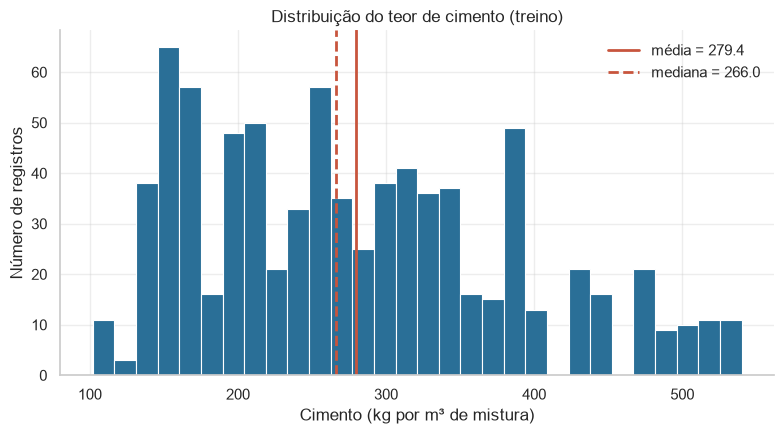

assimetria (skew): 0.533 | mín/máx: 102.0 540.0


In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df_treino["cimento"], bins=30, color=COR_PRINCIPAL, edgecolor="white", linewidth=0.8)
ax.axvline(df_treino["cimento"].mean(), color=COR_DESTAQUE, lw=2, label=f"média = {df_treino['cimento'].mean():.1f}")
ax.axvline(df_treino["cimento"].median(), color=COR_DESTAQUE, lw=2, ls="--", label=f"mediana = {df_treino['cimento'].median():.1f}")
ax.set_title("Distribuição do teor de cimento (treino)")
ax.set_xlabel("Cimento (kg por m³ de mistura)")
ax.set_ylabel("Número de registros")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "01_histograma_cimento.png", bbox_inches="tight")
plt.show()
print("assimetria (skew):", round(df_treino["cimento"].skew(), 3), "| mín/máx:", df_treino["cimento"].min(), df_treino["cimento"].max())

**Interpretação.** O teor de cimento no treino vai de 102 a 540 kg/m³, com média (279,4) acima da mediana (266,0) e assimetria positiva de 0,53, ou seja, uma cauda mais longa para teores altos. O histograma tem vários picos (por exemplo, perto de 150–170, 250 e 380 kg/m³), o que sugere que a base reúne **famílias de misturas** definidas em experimentos, e não uma população contínua e regular. Não há zeros: todas as misturas têm cimento. Não removemos valores extremos; essa variação é informação do domínio.

### 10.2 Distribuição do alvo: resistência à compressão

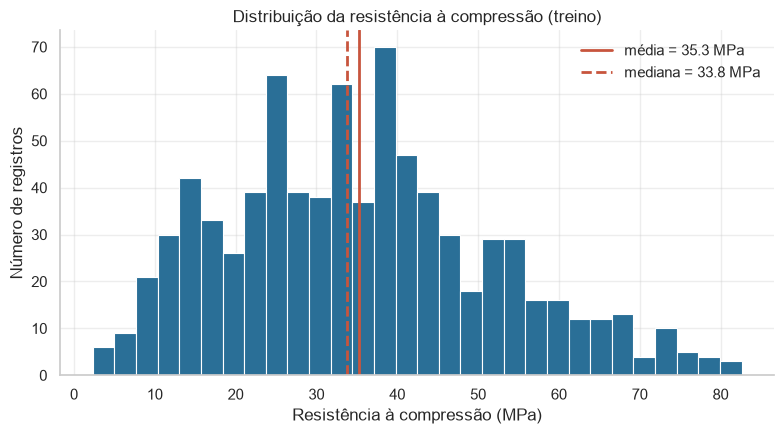

count    803.00
mean      35.31
std       16.53
min        2.33
25%       23.52
50%       33.76
75%       45.19
max       82.60
assimetria (skew): 0.42


In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df_treino[ALVO], bins=30, color=COR_PRINCIPAL, edgecolor="white", linewidth=0.8)
ax.axvline(df_treino[ALVO].mean(), color=COR_DESTAQUE, lw=2, label=f"média = {df_treino[ALVO].mean():.1f} MPa")
ax.axvline(df_treino[ALVO].median(), color=COR_DESTAQUE, lw=2, ls="--", label=f"mediana = {df_treino[ALVO].median():.1f} MPa")
ax.set_title("Distribuição da resistência à compressão (treino)")
ax.set_xlabel("Resistência à compressão (MPa)")
ax.set_ylabel("Número de registros")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "02_histograma_resistencia.png", bbox_inches="tight")
plt.show()
print(df_treino[ALVO].describe().round(2).to_string())
print("assimetria (skew):", round(df_treino[ALVO].skew(), 3))

**Interpretação.** A resistência (alvo) no treino varia de 2,33 a 82,60 MPa, com média de 35,3 e mediana de 33,8 MPa. A distribuição é aproximadamente unimodal, com leve assimetria à direita (0,42) e uma cauda de poucos valores acima de 70 MPa. Não há resistência zero. Como o alvo é contínuo e sem desbalanceamento de classes, a regressão é adequada; as métricas serão interpretadas em MPa. As resistências mais altas são poucas, então erros nessa região tendem a ser maiores por haver menos exemplos — isto é uma hipótese a verificar na avaliação, não um resultado.

### 10.3 Matriz de correlação (entradas e alvo)

Correlação de Pearson, que mede associação **linear**; relações não lineares podem passar despercebidas.

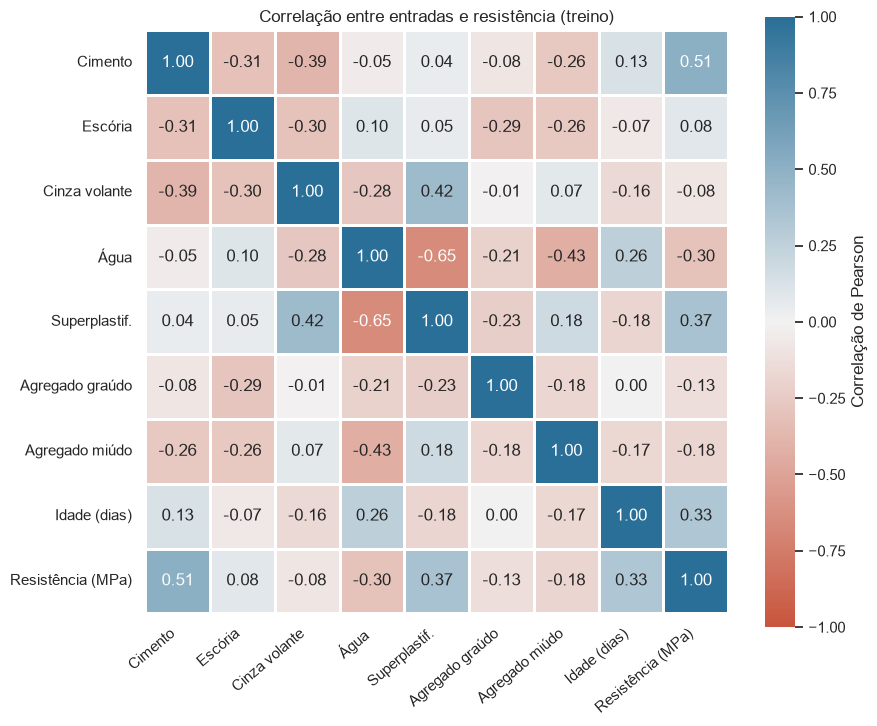

cimento               0.515
superplastificante    0.366
idade_dias            0.334
escoria               0.079
cinza_volante        -0.080
agregado_graudo      -0.127
agregado_miudo       -0.183
agua                 -0.304

Maiores |correlações| entre pares:
agua           superplastificante   -0.652
cimento        resistencia_mpa       0.515
agua           agregado_miudo       -0.432
cinza_volante  superplastificante    0.420
cimento        cinza_volante        -0.388


In [17]:
ROTULOS = {"cimento": "Cimento", "escoria": "Escória", "cinza_volante": "Cinza volante", "agua": "Água",
           "superplastificante": "Superplastif.", "agregado_graudo": "Agregado graúdo",
           "agregado_miudo": "Agregado miúdo", "idade_dias": "Idade (dias)", "resistencia_mpa": "Resistência (MPa)"}
corr = df_treino.corr(method="pearson")
cmap_div = LinearSegmentedColormap.from_list("div", ["#c8553d", "#f2f2f2", "#2a6f97"])   # dois polos + meio neutro

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr.rename(index=ROTULOS, columns=ROTULOS), annot=True, fmt=".2f", cmap=cmap_div, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", square=True, cbar_kws={"label": "Correlação de Pearson"}, ax=ax)
ax.set_title("Correlação entre entradas e resistência (treino)")
plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "03_matriz_correlacao.png", bbox_inches="tight")
plt.show()
print(corr[ALVO].drop(ALVO).sort_values(ascending=False).round(3).to_string())
print()
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print("Maiores |correlações| entre pares:")
print(pares.reindex(pares.abs().sort_values(ascending=False).index).head(5).round(3).to_string())

**Interpretação.** Ordenando pela correlação de Pearson com a resistência (treino): cimento **+0,51**, superplastificante **+0,37**, idade **+0,33**, água **−0,30**, agregado miúdo −0,18, agregado graúdo −0,13, cinza volante −0,08 e escória +0,08. O cimento é a entrada mais associada ao alvo, mas nenhuma correlação é maior que 0,51, e isso mostra que **nenhuma variável isolada explica a resistência**; ela depende da combinação dos componentes e da idade. Entre as entradas, o par mais correlacionado é água × superplastificante (**−0,65**): misturas com mais aditivo tendem a ter menos água. Essa associação entre entradas pode dificultar a leitura de coeficientes de modelos lineares. **Atenção:** correlação mede associação linear e **não prova causalidade**; por exemplo, a correlação positiva do superplastificante com a resistência pode refletir a redução de água que ele acompanha, e não um efeito direto. Relações não lineares (como as da idade) podem estar subestimadas.

### 10.4 Domínio: idade do concreto × resistência

A idade (dias de cura) é uma variável de domínio central. À direita, o mesmo gráfico com a idade em escala logarítmica, que separa melhor os pontos concentrados nas idades baixas.

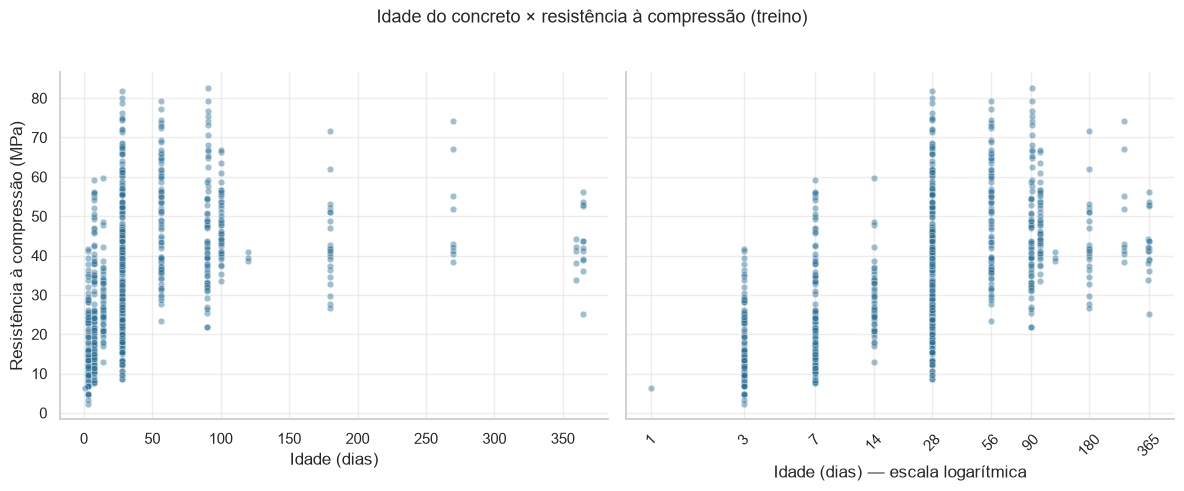

Idades distintas: 14


,n,mediana,minimo,maximo
idade_dias,,,,
28,330,33.5,8.5,81.8
7,100,21.3,7.5,59.1
3,95,14.9,2.3,41.6
56,72,49.9,23.2,79.4
14,49,26.8,12.8,59.8
90,47,39.7,21.9,58.8
100,42,47.0,33.6,66.9
180,22,41.4,26.7,71.6


In [18]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, log in zip(eixos, [False, True]):
    ax.scatter(df_treino["idade_dias"], df_treino[ALVO], s=22, alpha=0.45, color=COR_PRINCIPAL, edgecolor="white", linewidth=0.4)
    ax.set_xlabel("Idade (dias)" + (" — escala logarítmica" if log else ""))
    if log:
        ax.set_xscale("log")
        ax.set_xticks([1, 3, 7, 14, 28, 56, 90, 180, 365])
        ax.xaxis.set_major_formatter(ScalarFormatter())
        ax.tick_params(axis="x", labelrotation=45)
eixos[0].set_ylabel("Resistência à compressão (MPa)")
fig.suptitle("Idade do concreto × resistência à compressão (treino)", y=1.02, fontsize=13)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "04_dispersao_idade_resistencia.png", bbox_inches="tight")
plt.show()
resumo_idade = df_treino.groupby("idade_dias")[ALVO].agg(n="size", mediana="median", minimo="min", maximo="max").round(1)
print("Idades distintas:", len(resumo_idade))
resumo_idade.sort_values("n", ascending=False).head(8)

**Interpretação.** Há só **14 idades distintas** no treino, e a de 28 dias concentra 330 dos 803 registros (41 %). A resistência mediana cresce das idades curtas para as longas: 14,9 MPa aos 3 dias, 21,3 aos 7, 33,5 aos 28 e 49,9 aos 56 dias. Depois disso o padrão não é monotônico (mediana de 39,7 aos 90 dias, 47,0 aos 100 e 41,4 aos 180), o que indica que as misturas medidas em idades longas **não são as mesmas** das de idades curtas. Em cada idade a dispersão é grande (aos 28 dias, de 8,5 a 81,8 MPa), logo a idade sozinha não determina a resistência: a composição pesa muito. A relação com a idade é claramente **não linear** (crescimento rápido no início e depois estabilização), motivo pelo qual a correlação linear de 0,33 subestima sua importância. Isto é uma associação observada nos dados, e não uma lei causal estimada.

### Resumo até aqui

- Abas extras vazias; dados originais intactos.
- Base de trabalho com 1005 linhas (25 duplicatas exatas removidas). Entradas iguais com alvos diferentes, zeros legítimos e valores extremos foram mantidos.
- Separação por grupos (`GroupShuffleSplit`, 20 %, `random_state=42`): 803 linhas no treino e 202 no teste, sem grupos em comum.
- EDA feita só no treino, com quatro gráficos salvos em `reports/figures/`.
- Sem *encoding*, porque todas as entradas são numéricas. Imputador e *scaler* ficam dentro dos pipelines da modelagem, para não vazar estatísticas do teste.

Na sequência: Ridge e Random Forest comparados com `GroupKFold` (5 folds) no treino, escolha do modelo, avaliação única no teste e exportação com `joblib`.

### Pasta de modelos e ambiente

Cria a pasta `models/` (se ainda não existir) e mostra qual Python e qual versão do scikit-learn estão em uso. As importações ficam todas na primeira célula de código.

In [19]:
DIR_MODELOS = RAIZ / 'models'
DIR_MODELOS.mkdir(parents=True, exist_ok=True)
print('Python:', platform.python_version())
print('scikit-learn:', sklearn.__version__)
print('Bibliotecas disponíveis. Nenhum treinamento nesta célula.')


Python: 3.12.10
scikit-learn: 1.9.1
Bibliotecas disponíveis. Nenhum treinamento nesta célula.


## 11. Modelagem e comparação no treino

**Ridge:** modelo linear regularizado; é uma comparação simples e interpretável.
**Random Forest:** combinação de árvores, capaz de capturar relações não lineares e interações.
**Baseline da média:** referência simples para saber se os modelos acrescentam valor.

Configurações iniciais fixadas antes do teste: Ridge com `alpha=1.0`; Random Forest com 200 árvores,
`min_samples_leaf=2` e seed 42. Não fizemos busca de hiperparâmetros.

O mesmo pipeline contém **imputador → scaler → estimador**. O Ridge se beneficia da padronização.
Árvores não a exigem; ela é mantida no Random Forest para ter um fluxo comum e exportar o scaler
explicitamente, conforme o enunciado. Essa escolha também é registrada no relatório.
Todos os transformadores são ajustados apenas nos dados de treino de cada fold.

### 11.1 — Definir os pipelines sem treinar

A definição organiza as operações, mas não chama `fit`. Cada avaliação receberá uma cópia do pipeline, ajustada dentro dos folds.

In [20]:
def criar_pipeline(estimador):
    return Pipeline([
        ('imputador', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('modelo', estimador),
    ])

pipelines = {
    'Ridge': criar_pipeline(Ridge(alpha=1.0)),
    'Random Forest': criar_pipeline(RandomForestRegressor(
        n_estimators=200, min_samples_leaf=2, random_state=SEED, n_jobs=1)),
    'Baseline (média)': criar_pipeline(DummyRegressor(strategy='mean')),
}
for nome, pipeline in pipelines.items():
    print(nome, '→', ' → '.join(pipeline.named_steps))
print('Pipelines definidos. Nenhum modelo foi treinado nesta célula.')


Ridge → imputador → scaler → modelo
Random Forest → imputador → scaler → modelo
Baseline (média) → imputador → scaler → modelo
Pipelines definidos. Nenhum modelo foi treinado nesta célula.


### 11.2 — Preparar cinco folds sem misturar grupos

Prepara as mesmas cinco divisões para todos os modelos e uma função de avaliação. `GroupKFold` sem embaralhamento é determinístico; por isso não recebe random_state. A tabela confirma que não há grupos compartilhados dentro dos folds.

In [21]:
cv = GroupKFold(n_splits=5)
dobras = list(cv.split(X_treino, y_treino, groups=grupos_treino))
resumo_dobras = []
for numero, (pos_fit, pos_validacao) in enumerate(dobras, start=1):
    repetidos = (set(grupos_treino.iloc[pos_fit])
                 & set(grupos_treino.iloc[pos_validacao]))
    assert not repetidos, 'Há um grupo nos dois lados do fold.'
    resumo_dobras.append({'fold': numero, 'linhas para ajuste': len(pos_fit),
                         'linhas para validação': len(pos_validacao),
                         'grupos em comum': len(repetidos)})
display(pd.DataFrame(resumo_dobras))

SCORING = {'rmse': 'neg_root_mean_squared_error',
           'mae': 'neg_mean_absolute_error', 'r2': 'r2'}
resultados_cv = {}

def avaliar_cv(nome):
    if '_AVALIACAO_FINAL' in globals():
        raise RuntimeError('O teste final já foi visto nesta sessão. '
                           'Não refaça a seleção com base nele.')
    print(f'Iniciando {nome}: cinco ajustes e validações somente no treino...')
    resultados = cross_validate(pipelines[nome], X_treino, y_treino,
                               cv=dobras, scoring=SCORING,
                               n_jobs=1, error_score='raise')
    resultados_cv[nome] = resultados
    tabela_folds = pd.DataFrame({'fold': range(1, 6),
                                'RMSE (MPa)': -resultados['test_rmse'],
                                'MAE (MPa)': -resultados['test_mae'],
                                'R²': resultados['test_r2']})
    display(tabela_folds.round(4))
    print('RMSE médio:', round(tabela_folds['RMSE (MPa)'].mean(), 4), 'MPa')
    print('Aqui, test_rmse significa a validação do fold; não é o teste reservado.')


,fold,linhas para ajuste,linhas para validação,grupos em comum
0,1,642,161,0
1,2,642,161,0
2,3,642,161,0
3,4,643,160,0
4,5,643,160,0


### 11.3 — Treinar e validar o Ridge

Esta é a primeira célula que efetivamente treina modelos. Ajusta cinco pipelines Ridge e mede seu desempenho nas cinco partes de validação do treino.

In [22]:
avaliar_cv('Ridge')


Iniciando Ridge: cinco ajustes e validações somente no treino...


,fold,RMSE (MPa),MAE (MPa),R²
0,1,9.3908,7.9066,0.6866
1,2,10.6428,8.2899,0.5831
2,3,10.9585,8.5821,0.5295
3,4,10.1166,8.0025,0.6452
4,5,10.5351,8.2050,0.5832


RMSE médio: 10.3288 MPa
Aqui, test_rmse significa a validação do fold; não é o teste reservado.


### 11.4 — Treinar e validar o Random Forest

Treina cinco florestas nas mesmas divisões. Esta célula pode demorar mais porque cada ajuste constrói 200 árvores.

In [23]:
avaliar_cv('Random Forest')


Iniciando Random Forest: cinco ajustes e validações somente no treino...


,fold,RMSE (MPa),MAE (MPa),R²
0,1,5.1847,3.7661,0.9045
1,2,5.1791,3.8871,0.9013
2,3,5.6394,4.0304,0.8754
3,4,5.4407,3.8278,0.8974
4,5,6.4447,4.2850,0.8440


RMSE médio: 5.5777 MPa
Aqui, test_rmse significa a validação do fold; não é o teste reservado.


### 11.5 — Medir a referência da média

Em cada fold, prevê a média do alvo do respectivo treino. Ajuda a interpretar o ganho obtido pelos modelos.

In [24]:
avaliar_cv('Baseline (média)')


Iniciando Baseline (média): cinco ajustes e validações somente no treino...


,fold,RMSE (MPa),MAE (MPa),R²
0,1,16.7856,13.4432,-0.0012
1,2,16.5016,13.8480,-0.0021
2,3,15.9892,12.6910,-0.0016
3,4,16.9864,13.9015,-0.0004
4,5,16.3259,12.8205,-0.0009


RMSE médio: 16.5177 MPa
Aqui, test_rmse significa a validação do fold; não é o teste reservado.


### 11.6 — Comparar resultados da validação cruzada

Transforma os scorers negativos em erros positivos e calcula média e desvio-padrão entre folds. O desvio entre folds descreve variação; não é um intervalo de confiança da previsão.

In [25]:
faltantes = set(pipelines) - set(resultados_cv)
if faltantes:
    raise RuntimeError(f'Execute as avaliações pendentes: {sorted(faltantes)}')

linhas_cv = []
for nome, valores in resultados_cv.items():
    rmse = -valores['test_rmse']
    mae = -valores['test_mae']
    r2 = valores['test_r2']
    linhas_cv.append({'modelo': nome,
                      'RMSE médio (MPa)': float(rmse.mean()),
                      'RMSE desvio (MPa)': float(rmse.std(ddof=1)),
                      'MAE médio (MPa)': float(mae.mean()),
                      'MAE desvio (MPa)': float(mae.std(ddof=1)),
                      'R² médio': float(r2.mean()),
                      'R² desvio': float(r2.std(ddof=1))})
tabela_cv = pd.DataFrame(linhas_cv).set_index('modelo').sort_values('RMSE médio (MPa)')
display(tabela_cv.round(4))
tabela_cv.to_csv(RAIZ / 'reports' / 'comparacao_modelos_cv.csv')
print('Tabela de CV salva em reports/comparacao_modelos_cv.csv')


,RMSE médio (MPa),RMSE desvio (MPa),MAE médio (MPa),MAE desvio (MPa),R² médio,R² desvio
modelo,,,,,,
Random Forest,5.5777,0.5214,3.9593,0.2067,0.8845,0.0253
Ridge,10.3288,0.6047,8.1972,0.2642,0.6055,0.0611
Baseline (média),16.5177,0.3898,13.3408,0.5646,-0.0012,0.0007


Tabela de CV salva em reports/comparacao_modelos_cv.csv


### 11.7 — Escolher o modelo antes de abrir o teste

Aplica o critério já definido, entre Ridge e Random Forest. O teste permanece reservado; a baseline serve só como referência.

In [26]:
if '_AVALIACAO_FINAL' in globals():
    raise RuntimeError('A avaliação final já ocorreu. Preserve a decisão anterior.')
candidatos = tabela_cv.loc[['Ridge', 'Random Forest']].sort_values('RMSE médio (MPa)')
nome_escolhido = candidatos.index[0]
rmse_cv_escolhido = float(candidatos.iloc[0]['RMSE médio (MPa)'])
print('Escolhido:', nome_escolhido)
print('Critério: menor RMSE médio de validação cruzada entre os dois modelos reais.')
print('RMSE médio de CV:', round(rmse_cv_escolhido, 4), 'MPa')
print('O conjunto de teste ainda não foi avaliado.')


Escolhido: Random Forest
Critério: menor RMSE médio de validação cruzada entre os dois modelos reais.
RMSE médio de CV: 5.5777 MPa
O conjunto de teste ainda não foi avaliado.


**Justificativa da modelagem**

- **Baseline.** Prever sempre a média do treino dá RMSE de 16,52 MPa e R² próximo de zero. Os dois modelos ficam bem abaixo disso: 10,33 MPa (Ridge) e 5,58 MPa (Random Forest).
- **Ridge × Random Forest.** A diferença média de RMSE é de cerca de 4,7 MPa, bem maior que o desvio entre folds (0,6 e 0,5 MPa). Com apenas cinco folds não há teste estatístico, mas a distância é grande para ser atribuída à variação das divisões.
- **Modelo escolhido.** Random Forest, pelo menor RMSE médio de validação cruzada. O critério foi fixado antes de abrir o teste. O resultado é coerente com a EDA: a idade tem relação não linear com a resistência e os componentes interagem, o que um modelo linear captura mal.
- **Limitações da validação.** Hiperparâmetros fixos, sem busca; cinco folds; e o agrupamento pelas oito entradas não impede a mesma composição em idades diferentes de aparecer em folds distintos.

## 12. Avaliação final do modelo escolhido


### 12.1 — Treinar o escolhido em todo o treino

Os cinco ajustes de CV serviam para comparar os modelos. Agora ajustamos uma cópia do escolhido em todo o treino disponível. Não treinamos usando o conjunto de teste.

In [27]:
if '_AVALIACAO_FINAL' in globals():
    pipeline_final = _AVALIACAO_FINAL['pipeline']
    print('Mantido o pipeline já avaliado nesta sessão.')
else:
    pipeline_final = clone(pipelines[nome_escolhido])
    pipeline_final.fit(X_treino, y_treino)
    print(nome_escolhido, 'ajustado em', len(X_treino), 'linhas de treino.')
    print('Imputador, scaler e modelo foram ajustados somente no treino.')
    print('O teste ainda não foi usado para medir o desempenho.')


Random Forest ajustado em 803 linhas de treino.
Imputador, scaler e modelo foram ajustados somente no treino.
O teste ainda não foi usado para medir o desempenho.


### 12.2 — Prever o teste e calcular as três métricas

Usa as mesmas previsões para RMSE, MAE e R². Na primeira execução a célula calcula as previsões do teste; nas seguintes ela só reexibe o resultado, para que o teste não seja usado mais de uma vez. Reiniciar o kernel remove essa trava, mas isso não autoriza ajustar o modelo olhando o teste.

In [28]:
if '_AVALIACAO_FINAL' not in globals():
    predicoes_teste = pipeline_final.predict(X_teste)
    metricas_teste = {
        'RMSE (MPa)': float(np.sqrt(mean_squared_error(y_teste, predicoes_teste))),
        'MAE (MPa)': float(mean_absolute_error(y_teste, predicoes_teste)),
        'R²': float(r2_score(y_teste, predicoes_teste)),
    }
    _AVALIACAO_FINAL = {'nome': nome_escolhido, 'pipeline': pipeline_final,
                       'predicoes': predicoes_teste, 'metricas': metricas_teste}
    print('Avaliação final realizada. A escolha anterior permanece fixa.')
else:
    print('Reexibindo a avaliação já calculada nesta sessão, sem nova avaliação.')

nome_escolhido = _AVALIACAO_FINAL['nome']
pipeline_final = _AVALIACAO_FINAL['pipeline']
predicoes_teste = _AVALIACAO_FINAL['predicoes']
metricas_teste = _AVALIACAO_FINAL['metricas']
display(pd.DataFrame([metricas_teste], index=[nome_escolhido]).round(4))
pd.DataFrame([{'modelo': nome_escolhido, **metricas_teste}]).to_csv(
    RAIZ / 'reports' / 'avaliacao_final_teste.csv', index=False)


Avaliação final realizada. A escolha anterior permanece fixa.


,RMSE (MPa),MAE (MPa),R²
Random Forest,4.6729,3.4416,0.9065


### 12.3 — Visualizar valores reais e previstos

Pontos próximos da diagonal representam previsões próximas do valor real. Usa as previsões já calculadas, sem ajustar novamente o modelo.

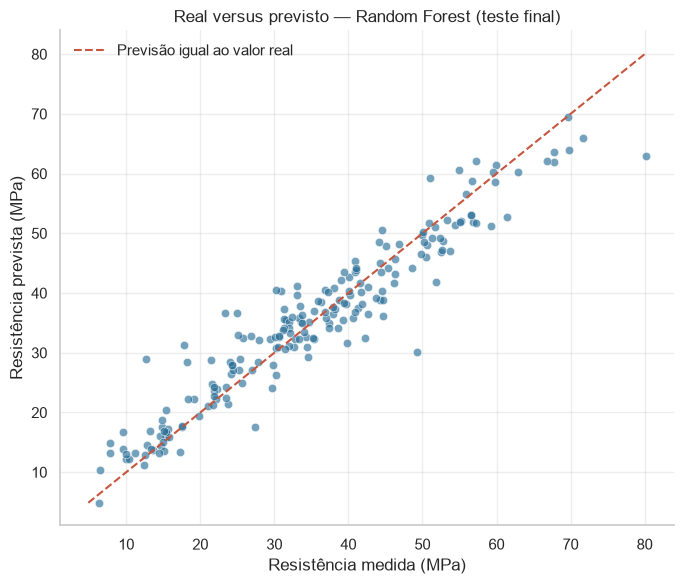

,real_mpa,predito_mpa,erro_absoluto_mpa
indice_original,,,
10,38.074,40.922,2.848
23,44.208,38.752,5.456
25,53.301,52.250,1.051
29,38.604,34.116,4.488
30,55.260,52.003,3.257


In [29]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(y_teste, predicoes_teste, alpha=0.65, color=COR_PRINCIPAL,
           edgecolor='white', linewidth=0.5)
limite_min = float(min(y_teste.min(), predicoes_teste.min()))
limite_max = float(max(y_teste.max(), predicoes_teste.max()))
ax.plot([limite_min, limite_max], [limite_min, limite_max],
        '--', color=COR_DESTAQUE, label='Previsão igual ao valor real')
ax.set_xlabel('Resistência medida (MPa)')
ax.set_ylabel('Resistência prevista (MPa)')
ax.set_title(f'Real versus previsto — {nome_escolhido} (teste final)')
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / '05_real_vs_predito.png', bbox_inches='tight')
plt.show()

tabela_predicoes = pd.DataFrame({'real_mpa': y_teste,
                                 'predito_mpa': predicoes_teste})
tabela_predicoes['erro_absoluto_mpa'] = (
    tabela_predicoes['real_mpa'] - tabela_predicoes['predito_mpa']).abs()
tabela_predicoes.index.name = 'indice_original'
tabela_predicoes.to_csv(RAIZ / 'reports' / 'predicoes_teste.csv')
display(tabela_predicoes.head().round(3))


**Interpretação da avaliação**

- **RMSE e MAE.** O RMSE de 4,67 MPa e o MAE de 3,44 MPa indicam que, em média, a previsão erra algo em torno de 3 a 5 MPa. O RMSE é maior porque pesa mais os erros grandes. O R² de 0,906 diz que o modelo explica cerca de 91 % da variação da resistência no conjunto de teste. O erro no teste ficou abaixo do da validação cruzada (5,58 MPa); com um único conjunto de 202 linhas e um treino maior, isso é plausível e não deve ser lido como melhora real.
- **Gráfico real × predito.** Os pontos se concentram em torno da diagonal e o viés médio é pequeno (cerca de +0,2 MPa). Nas pontas o modelo se afasta mais: abaixo de 20 MPa tende a superestimar (+2,6 MPa em média) e acima de 60 MPa tende a subestimar (−6,1 MPa, RMSE de 7,6 MPa, em apenas 9 pontos). É o comportamento esperado de uma floresta, que puxa as previsões para a média onde há poucos exemplos.
- **Alcance.** Os números mostram o desempenho neste conjunto de teste e neste protocolo. Não mostram que o modelo generaliza para receitas inéditas nem que serve para decisão estrutural.

## 13. Exportação e preparação para a interface


### 13.1 — Salvar pipeline, scaler e metainformações

Grava o pipeline completo e uma cópia auxiliar do scaler treinado para atender explicitamente à exportação de modelo e scaler. A API usará somente o pipeline para a previsão: não aplique o scaler separado antes dele. Limites e exemplo vêm do treino.

In [30]:
ARQUIVO_PIPELINE = DIR_MODELOS / 'pipeline.joblib'
ARQUIVO_SCALER = DIR_MODELOS / 'scaler.joblib'
ARQUIVO_METADATA = DIR_MODELOS / 'metadata.json'

joblib.dump(pipeline_final, ARQUIVO_PIPELINE)
joblib.dump(pipeline_final.named_steps['scaler'], ARQUIVO_SCALER)

limites_treino = {
    feature: {'min': float(X_treino[feature].min()),
              'max': float(X_treino[feature].max())}
    for feature in FEATURES
}
exemplo_treino = {
    feature: (int(X_treino.iloc[0][feature]) if feature == 'idade_dias'
              else float(X_treino.iloc[0][feature]))
    for feature in FEATURES
}
metadata_modelo = {
    'projeto': 'ConcretoAI', 'modelo': nome_escolhido,
    'features': list(FEATURES), 'alvo': ALVO, 'unidade_resultado': 'MPa',
    'unidades': UNIDADES, 'limites_operacionais_treino': limites_treino,
    'exemplo_treino': exemplo_treino, 'seed': SEED,
    'etapas_pipeline': list(pipeline_final.named_steps),
    'pipeline_inclui_scaler': True,
    'scaler_separado': 'Artefato auxiliar; não aplicar antes de pipeline.predict.',
    'rmse_medio_cv_mpa': rmse_cv_escolhido,
    'metricas_teste': metricas_teste,
    'split': {'metodo': 'GroupShuffleSplit', 'fracao_grupos_teste': 0.20,
              'grupos_por': list(FEATURES), 'linhas_treino': len(X_treino),
              'linhas_teste': len(X_teste)},
    'versoes': {'python': platform.python_version(), 'scikit-learn': sklearn.__version__,
                'numpy': np.__version__, 'pandas': pd.__version__, 'joblib': joblib.__version__},
    'fonte': 'https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength',
    'doi': 'https://doi.org/10.24432/C5PK67', 'licenca': 'CC BY 4.0',
    'credito': 'I-Cheng Yeh',
}
ARQUIVO_METADATA.write_text(json.dumps(metadata_modelo, ensure_ascii=False, indent=2),
                           encoding='utf-8')
for arquivo in (ARQUIVO_PIPELINE, ARQUIVO_SCALER, ARQUIVO_METADATA):
    print('Salvo:', arquivo.relative_to(RAIZ), '| bytes:', arquivo.stat().st_size)


Salvo: models\pipeline.joblib | bytes: 6384954
Salvo: models\scaler.joblib | bytes: 775
Salvo: models\metadata.json | bytes: 2502


### 13.2 — Recarregar e conferir a mesma previsão

Usa uma entrada do treino para verificar a persistência. É uma conferência do arquivo, não uma nova avaliação do desempenho no teste.

In [31]:
pipeline_carregado = joblib.load(ARQUIVO_PIPELINE)
entrada_exemplo = X_treino.iloc[[0]].copy()
previsao_memoria = pipeline_final.predict(entrada_exemplo)
previsao_recarga = pipeline_carregado.predict(entrada_exemplo)
np.testing.assert_allclose(previsao_memoria, previsao_recarga, rtol=1e-10, atol=1e-10)
display(entrada_exemplo)
print('Previsão em memória:', float(previsao_memoria[0]), 'MPa')
print('Previsão após recarga:', float(previsao_recarga[0]), 'MPa')
print('Conferência OK: mesmo resultado antes e depois de salvar.')


,cimento,escoria,cinza_volante,agua,superplastificante,agregado_graudo,agregado_miudo,idade_dias
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28


Previsão em memória: 69.28757188789699 MPa
Previsão após recarga: 69.28757188789699 MPa
Conferência OK: mesmo resultado antes e depois de salvar.


### 13.3 — Registrar as dependências do projeto

Registra as versões das dependências diretas do projeto, sem copiar todos os pacotes da venv compartilhada. A execução em ambiente limpo será a verificação de reprodutibilidade.

In [32]:
pacotes_projeto = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'seaborn',
                   'joblib', 'ipykernel', 'ipython', 'xlrd',
                   'fastapi', 'uvicorn', 'pydantic']
dependencias = []
for pacote in pacotes_projeto:
    dependencias.append(f'{pacote}=={package_metadata.version(pacote)}')
arquivo_requirements = RAIZ / 'requirements.txt'
arquivo_requirements.write_text('\n'.join(dependencias) + '\n', encoding='utf-8')
print(arquivo_requirements.read_text(encoding='utf-8'))
print('Registradas dependências diretas com as versões desta execução.')
print('Ainda será necessário verificar instalação e execução em ambiente limpo.')


pandas==3.0.6
numpy==2.5.3
scikit-learn==1.9.1
matplotlib==3.11.2
seaborn==0.13.2
joblib==1.6.0
ipykernel==7.3.0
ipython==9.17.1
xlrd==2.0.2
fastapi==0.142.2
uvicorn==0.54.0
pydantic==2.13.5

Registradas dependências diretas com as versões desta execução.
Ainda será necessário verificar instalação e execução em ambiente limpo.


### Integração com a interface

A interface (`app.py` + `static/index.html`) usa o modelo exportado da seguinte forma:

- carrega `models/pipeline.joblib` uma única vez ao iniciar;
- recebe as oito entradas em unidades originais, na ordem de `metadata.json`;
- monta um DataFrame com essas colunas e chama `pipeline.predict`, sem aplicar o scaler separado e sem chamar `fit`;
- devolve o valor previsto em MPa, sem inventar porcentagem de confiança;
- valida campo vazio, texto no lugar de número, valores não finitos, idade inteira positiva e os limites observados no treino.

Instalação e execução, na raiz do trabalho (PowerShell, com a venv ativa):

```powershell
python -m pip install -r requirements.txt
python -m uvicorn app:app --reload
```

## 14. Conclusão e revisão


### 14.1 — Síntese dos resultados desta execução

Monta a lista de conclusões com os valores calculados acima, para que o texto acompanhe a execução. O erro obtido não é classificado como aceitável ou não para uso prático, porque não há um critério externo de tolerância.

In [33]:
conclusao_linhas = [
    'O objetivo foi estimar a resistência à compressão a partir da composição e da idade.',
    'Foi utilizada a base pública Concrete Compressive Strength, da UCI, com crédito a I-Cheng Yeh.',
    f'A base lida contém {len(df)} registros; a base de trabalho contém {len(df_trab)}.',
    f'Foram removidas {n_antes - n_depois} duplicatas exatas por decisão documentada do projeto.',
    'Entradas iguais com alvos diferentes foram mantidas porque a causa das diferenças não foi comprovada.',
    'Zeros legítimos foram preservados e não foram descartados outliers automaticamente.',
    f'A separação reservou {len(X_treino)} linhas para treino e {len(X_teste)} para teste, sem grupos em comum.',
    'A EDA foi realizada no treino, com quatro gráficos; associações não foram tratadas como causalidade.',
    'Ridge e Random Forest foram comparados nos mesmos cinco folds por grupos, com uma baseline da média.',
    'Imputação e padronização foram ajustadas dentro dos pipelines para evitar vazamento de estatísticas.',
    f'O modelo escolhido foi {nome_escolhido}, com RMSE médio de CV de {rmse_cv_escolhido:.3f} MPa.',
    f'No teste final, RMSE = {metricas_teste["RMSE (MPa)"]:.3f} MPa, '
    f'MAE = {metricas_teste["MAE (MPa)"]:.3f} MPa e R² = {metricas_teste["R²"]:.3f}.',
    'Esses números descrevem este protocolo; não demonstram aprovação para uso estrutural.',
    'A mesma composição em idades diferentes pode estar em conjuntos distintos, limitando a generalização avaliada.',
    'Como melhoria, propõe-se avaliar grupos por composição e obter medições adicionais com contexto experimental.',
    'O pipeline exportado pode ser consumido por uma interface, sem retreinamento nem padronização duplicada.',
]
display(Markdown('\n'.join(f'{i}. {linha}' for i, linha in enumerate(conclusao_linhas, 1))))
(RAIZ / 'reports' / 'conclusao_resultados.md').write_text(
    '\n'.join(f'{i}. {linha}' for i, linha in enumerate(conclusao_linhas, 1)) + '\n',
    encoding='utf-8')


1. O objetivo foi estimar a resistência à compressão a partir da composição e da idade.
2. Foi utilizada a base pública Concrete Compressive Strength, da UCI, com crédito a I-Cheng Yeh.
3. A base lida contém 1030 registros; a base de trabalho contém 1005.
4. Foram removidas 25 duplicatas exatas por decisão documentada do projeto.
5. Entradas iguais com alvos diferentes foram mantidas porque a causa das diferenças não foi comprovada.
6. Zeros legítimos foram preservados e não foram descartados outliers automaticamente.
7. A separação reservou 803 linhas para treino e 202 para teste, sem grupos em comum.
8. A EDA foi realizada no treino, com quatro gráficos; associações não foram tratadas como causalidade.
9. Ridge e Random Forest foram comparados nos mesmos cinco folds por grupos, com uma baseline da média.
10. Imputação e padronização foram ajustadas dentro dos pipelines para evitar vazamento de estatísticas.
11. O modelo escolhido foi Random Forest, com RMSE médio de CV de 5.578 MPa.
12. No teste final, RMSE = 4.673 MPa, MAE = 3.442 MPa e R² = 0.906.
13. Esses números descrevem este protocolo; não demonstram aprovação para uso estrutural.
14. A mesma composição em idades diferentes pode estar em conjuntos distintos, limitando a generalização avaliada.
15. Como melhoria, propõe-se avaliar grupos por composição e obter medições adicionais com contexto experimental.
16. O pipeline exportado pode ser consumido por uma interface, sem retreinamento nem padronização duplicada.

1496

### Considerações finais

- **Principal achado da EDA.** Nenhuma variável isolada explica a resistência (a maior correlação, a do cimento, é de +0,51). A idade tem relação não linear, com crescimento rápido no início e estabilização depois, e a composição pesa muito dentro de cada idade.
- **Escolha do modelo.** O Random Forest reduziu o RMSE de validação de 10,33 MPa (Ridge) e 16,52 MPa (média) para 5,58 MPa, e a escolha foi feita antes de olhar o teste.
- **Resposta ao objetivo.** O modelo estima a resistência com erro típico de 3 a 5 MPa no teste (MAE 3,44; RMSE 4,67; R² 0,906), o que serve para uma estimativa exploratória, mas não substitui ensaio de laboratório.
- **Limitações e melhoria prioritária.** Os dados vêm de um único estudo, com poucas idades e muitas misturas repetidas em idades diferentes. O mais útil seria separar por composição inteira na validação e testar com medições novas.

**Referências técnicas**

- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html
- https://scikit-learn.org/stable/common_pitfalls.html
- https://scikit-learn.org/stable/model_persistence.html